# 02 — Building timestamps for each flight

**Question:** can we reconstruct full local timestamps (including arrival date) for every operated flight?

**Hypothesis:** the arrival time we derive from scheduled departure + scheduled elapsed time + time-zone offset must match the reported arrival time (`arr_hhmm`), which we do not use in the calculation.

In [1]:
from pathlib import Path

import duckdb
import pandas as pd

ROOT = Path.cwd().parent
PARQUET = ROOT / "data" / "parquet" / "*.parquet"

con = duckdb.connect()
con.execute(f"CREATE VIEW flights AS SELECT * FROM read_parquet('{PARQUET.as_posix()}')")

In [2]:
con.execute("""
CREATE OR REPLACE VIEW ops AS
WITH base AS (
    -- Operated flights only, with minutes since midnight for the scheduled times
    SELECT
        tail_number, carrier, flight_number, origin, dest, flight_date,
        crs_elapsed, dep_delay, arr_delay, arr_hhmm,
        (CAST(crs_dep_hhmm AS INTEGER) // 100) * 60 + CAST(crs_dep_hhmm AS INTEGER) % 100 AS crs_dep_tod,
        (CAST(crs_arr_hhmm AS INTEGER) // 100) * 60 + CAST(crs_arr_hhmm AS INTEGER) % 100 AS crs_arr_tod
    FROM flights
    WHERE NOT cancelled AND NOT diverted AND tail_number IS NOT NULL
),
tz AS (
    -- Time-zone difference (dest - origin), recovered from the data itself:
    -- scheduled arrival clock time - (scheduled departure clock time + scheduled elapsed time)
    SELECT *,
        ((crs_arr_tod % 1440 - crs_dep_tod % 1440 - crs_elapsed) % 1440 + 1440) % 1440 AS tz_raw
    FROM base
),
tz_signed AS (
    SELECT *, CASE WHEN tz_raw >= 720 THEN tz_raw - 1440 ELSE tz_raw END AS tz_offset_min
    FROM tz
)
SELECT
    tail_number, carrier, flight_number, origin, dest, flight_date, tz_offset_min, arr_hhmm,
    CAST(flight_date AS TIMESTAMP) + to_minutes(crs_dep_tod)                                           AS crs_dep_ts,
    CAST(flight_date AS TIMESTAMP) + to_minutes(crs_dep_tod + dep_delay)                               AS dep_ts,
    CAST(flight_date AS TIMESTAMP) + to_minutes(crs_dep_tod + crs_elapsed + tz_offset_min)             AS crs_arr_ts,
    CAST(flight_date AS TIMESTAMP) + to_minutes(crs_dep_tod + crs_elapsed + tz_offset_min + arr_delay) AS arr_ts,
    dep_delay, arr_delay, crs_elapsed
FROM tz_signed
""")

con.sql("SELECT count(*) AS n_operated_flights FROM ops").df()

,n_operated_flights
0,601570


In [3]:
con.sql("""
    SELECT tz_offset_min / 60 AS tz_hours, count(*) AS n_flights
    FROM ops
    GROUP BY 1
    ORDER BY 1
""").df()

,tz_hours,n_flights
0,-6.000000,113
1,-5.000000,189
2,-4.000000,260
3,-3.000000,23158
4,-2.000000,31211
5,-1.000000,94027
6,0.000000,303559
7,0.166667,1
8,0.666667,1
9,1.000000,94089


In [4]:
con.sql("""
    SELECT
        count(*) AS n_checked,
        sum((((hour(arr_ts) * 60 + minute(arr_ts))
              - ((CAST(arr_hhmm AS INTEGER) // 100) * 60 + CAST(arr_hhmm AS INTEGER) % 100)) % 1440 <> 0)::INT) AS n_mismatch
    FROM ops
""").df()

,n_checked,n_mismatch
0,601570,1.0


**Findings**
- Reconstructed arrival time matches the reported arrival time in 601,569 of 601,570 operated flights.
- Time-zone offsets recovered from the data are whole hours between -6 and +6, except 2 flights (10 and 40 min), most likely errors in the scheduled elapsed time. These will be excluded.
- Timestamps are local to each airport. This is enough to measure turnarounds: the previous arrival and the next departure of an aircraft happen at the same airport, so both use the same clock.

## Chaining flights into aircraft rotations

**Hypothesis:** consecutive flights of the same aircraft are geographically continuous (previous destination = next origin) in the vast majority of cases.

In [5]:
con.execute("""
CREATE OR REPLACE VIEW legs AS
SELECT *,
    LAG(carrier)       OVER w AS prev_carrier,
    LAG(flight_number) OVER w AS prev_flight_number,
    LAG(dest)          OVER w AS prev_dest,
    LAG(crs_arr_ts)    OVER w AS prev_crs_arr_ts,
    LAG(arr_ts)        OVER w AS prev_arr_ts,
    LAG(arr_delay)     OVER w AS prev_arr_delay
FROM ops
WHERE tz_offset_min % 60 = 0
WINDOW w AS (PARTITION BY tail_number ORDER BY crs_dep_ts, flight_number)
""")

In [6]:
con.sql("""
    SELECT
        count(*)                                      AS n_legs,
        sum((prev_dest IS NULL)::INT)                 AS n_first_of_aircraft,
        sum((prev_dest = origin)::INT)                AS n_continuous,
        sum((prev_dest <> origin)::INT)               AS n_broken,
        round(100.0 * sum((prev_dest = origin)::INT)
              / sum((prev_dest IS NOT NULL)::INT), 2) AS pct_continuous
    FROM legs
""").df().T

,0
n_legs,601568.00
n_first_of_aircraft,5680.00
n_continuous,585577.00
n_broken,10311.00
pct_continuous,98.27


In [7]:
con.sql("""
    SELECT
        sum((prev_crs_arr_ts > crs_dep_ts)::INT) AS n_negative_scheduled_turn,
        sum((prev_arr_ts > dep_ts)::INT)         AS n_negative_actual_turn
    FROM legs
    WHERE prev_dest = origin
""").df()

,n_negative_scheduled_turn,n_negative_actual_turn
0,5296.0,218.0


**Findings**
- 98.27% of consecutive flight pairs of the same aircraft are geographically continuous (585,577 of 595,888). Tail numbers reliably identify aircraft.
- 10,311 pairs (1.7%) are broken (previous destination ≠ next origin), probably legs missing from the BTS data. Excluded from propagation analysis.
- 5,296 continuous pairs have a negative *scheduled* turnaround, most likely aircraft swaps after the schedule was built: no scheduled buffer can be measured. Excluded.
- 218 continuous pairs have a negative *actual* turnaround (data errors). Excluded.
- Rotation dataset = continuous pairs with non-negative scheduled and actual turnaround.

## Where does a rotation chain end?

**Hypothesis:** ground times are bimodal (same-day turnarounds vs. overnight stays), and the share of delay passed from one flight to the next falls as ground time grows. The cut-off should sit in the valley between the two modes.

In [8]:
con.execute("""
CREATE OR REPLACE VIEW rot AS
SELECT *,
    date_diff('minute', prev_crs_arr_ts, crs_dep_ts) AS sched_turn_min,
    date_diff('minute', prev_arr_ts, dep_ts)         AS actual_turn_min
FROM legs
WHERE prev_dest = origin
  AND prev_crs_arr_ts <= crs_dep_ts
  AND prev_arr_ts <= dep_ts
""")

con.sql("SELECT count(*) AS n_rotation_pairs FROM rot").df()

,n_rotation_pairs
0,580201


In [16]:
import logging

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # silence missing-font warnings

BRAND = {"black": "#0D0D0D", "yellow": "#F5C518", "white": "#FFFFFF", "grey": "#8C8C8C", "grid": "#262626"}
TITLE_FONT = ["Space Grotesk", "Inter 18pt", "DejaVu Sans"]

plt.rcParams.update({
    "figure.facecolor": BRAND["black"], "axes.facecolor": BRAND["black"], "savefig.facecolor": BRAND["black"],
    "axes.edgecolor": BRAND["grid"], "axes.labelcolor": BRAND["grey"],
    "xtick.color": BRAND["grey"], "ytick.color": BRAND["grey"], "text.color": BRAND["white"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": BRAND["grid"], "grid.linewidth": 1,
    "axes.axisbelow": True,
        "font.family": "sans-serif", "font.sans-serif": ["Inter 18pt", "DejaVu Sans"],
})

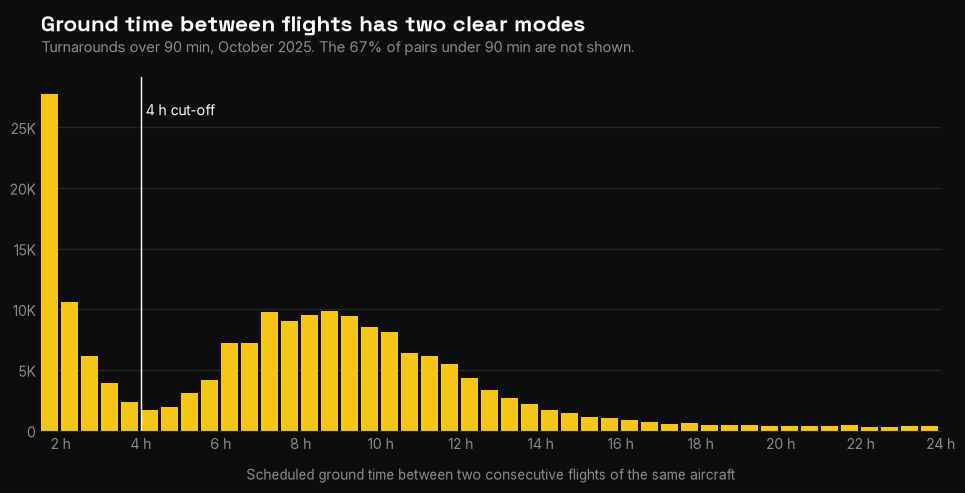

In [17]:
hist = con.sql("""
    SELECT (sched_turn_min // 30) * 30 AS bin_start_min, count(*) AS n_pairs
    FROM rot
    WHERE sched_turn_min >= 90 AND sched_turn_min < 1440
    GROUP BY 1
    ORDER BY 1
""").df()
short_share = con.sql("SELECT round(100.0 * avg((sched_turn_min < 90)::INT), 0) FROM rot").fetchone()[0]

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.bar(hist["bin_start_min"] / 60, hist["n_pairs"], width=0.44, align="edge", color=BRAND["yellow"])
ax.axvline(4, color=BRAND["white"], linewidth=1)
ax.text(4.12, ax.get_ylim()[1] * 0.93, "4 h cut-off", color=BRAND["white"], fontsize=10, va="top")

ax.set_xlim(1.5, 24)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} h"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}K" if v else "0"))
ax.tick_params(length=0)
ax.set_xlabel("Scheduled ground time between two consecutive flights of the same aircraft", labelpad=10)

fig.text(0.07, 0.95, "Ground time between flights has two clear modes", fontsize=16, fontweight="bold",
         fontfamily=TITLE_FONT, ha="left", va="top")
fig.text(0.07, 0.895, f"Turnarounds over 90 min, October 2025. The {short_share:.0f}% of pairs under 90 min are not shown.",
         fontsize=10.5, color=BRAND["grey"], ha="left", va="top")
fig.subplots_adjust(left=0.07, right=0.97, top=0.82, bottom=0.14)

fig.savefig(ROOT / "figures" / "turnaround_distribution.png", dpi=150)
plt.show()

In [11]:
con.sql("""
    SELECT
        CASE WHEN sched_turn_min < 60  THEN '1) 0-60 min'
             WHEN sched_turn_min < 120 THEN '2) 60-120 min'
             WHEN sched_turn_min < 180 THEN '3) 2-3 h'
             WHEN sched_turn_min < 240 THEN '4) 3-4 h'
             WHEN sched_turn_min < 360 THEN '5) 4-6 h'
             WHEN sched_turn_min < 600 THEN '6) 6-10 h'
             ELSE '7) 10 h+' END                         AS turn_band,
        count(*)                                         AS n_pairs,
        round(regr_slope(dep_delay, prev_arr_delay), 3)  AS slope
    FROM rot
    GROUP BY 1
    ORDER BY 1
""").df()

,turn_band,n_pairs,slope
0,1) 0-60 min,244906,0.904
1,2) 60-120 min,171791,0.688
2,3) 2-3 h,16716,0.374
3,4) 3-4 h,6331,0.261
4,5) 4-6 h,10935,0.199
5,6) 6-10 h,70635,0.116
6,7) 10 h+,58887,0.041


**Findings**
- Scheduled ground time is bimodal: same-day turnarounds (mostly under 3 h) and overnight stays (mostly 6–12 h), with a valley around 4–5 h.
- The share of delay passed on to the next flight falls steadily with ground time: 0.90 (under 1 h), 0.69 (1–2 h), 0.37 (2–3 h), 0.26 (3–4 h), 0.20 (4–6 h), 0.12 (6–10 h), 0.04 (10 h+). There is no sharp break, only a gradual decay.
- Decision: pairs with a scheduled ground time of up to 4 h are treated as the same-day rotation chain, where propagation is analysed. Longer gaps are kept as a comparison group.
- Caveat: the slope measures association, not pure causality. Shared causes (weather or congestion at the same airport) also link both delays. The long-gap pairs give a rough idea of this baseline.

## How much delay does ground time absorb?

For an aircraft that arrives late, the delay absorbed before its next departure equals scheduled ground time minus actual ground time: the aircraft recovers time by turning around faster.

**Hypothesis:** the longer the scheduled ground time, the larger the share of the inbound delay that is absorbed, up to a ceiling set by the minimum feasible turnaround.

In [18]:
con.sql("""
    SELECT
        count(*) AS n_pairs,
        sum(((prev_arr_delay - dep_delay) <> (sched_turn_min - actual_turn_min))::INT) AS n_mismatch
    FROM rot
""").df()

,n_pairs,n_mismatch
0,580201,0.0


In [19]:
con.execute("""
CREATE OR REPLACE VIEW late_inbound AS
SELECT *,
    prev_arr_delay - dep_delay AS absorbed_min
FROM rot
WHERE sched_turn_min >= 30 AND sched_turn_min < 240
  AND prev_arr_delay >= 15
""")

In [20]:
curve = con.sql("""
    SELECT
        (sched_turn_min // 30) * 30                                   AS turn_band_min,
        count(*)                                                      AS n_pairs,
        round(avg(prev_arr_delay), 1)                                 AS avg_inherited_min,
        round(avg(dep_delay), 1)                                      AS avg_dep_delay_min,
        round(100.0 * sum(absorbed_min) / sum(prev_arr_delay), 1)     AS absorbed_pct
    FROM late_inbound
    GROUP BY 1
    ORDER BY 1
""").df()
curve

,turn_band_min,n_pairs,avg_inherited_min,avg_dep_delay_min,absorbed_pct
0,30,42095,49.0,53.5,-9.2
1,60,23435,47.0,39.0,17.1
2,90,5449,53.3,24.8,53.5
3,120,2380,64.5,23.8,63.1
4,150,1581,75.7,18.0,76.3
5,180,1119,85.5,20.3,76.2
6,210,692,94.3,15.8,83.2


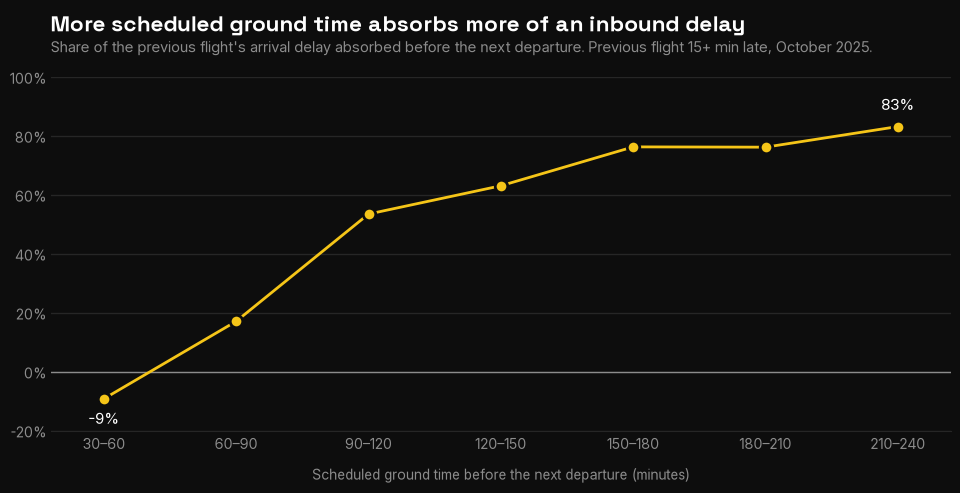

In [21]:
labels = [f"{a}–{a + 30}" for a in curve["turn_band_min"]]
x = range(len(curve))

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.axhline(0, color=BRAND["grey"], linewidth=1)
ax.plot(x, curve["absorbed_pct"], color=BRAND["yellow"], linewidth=2, solid_capstyle="round", solid_joinstyle="round")
ax.plot(x, curve["absorbed_pct"], linestyle="none", marker="o", markersize=9, markerfacecolor=BRAND["yellow"],
        markeredgecolor=BRAND["black"], markeredgewidth=2)

first, last = curve["absorbed_pct"].iloc[0], curve["absorbed_pct"].iloc[-1]
ax.annotate(f"{first:.0f}%", (0, first), textcoords="offset points", xytext=(0, -18), ha="center", color=BRAND["white"], fontsize=11)
ax.annotate(f"{last:.0f}%", (len(curve) - 1, last), textcoords="offset points", xytext=(0, 12), ha="center", color=BRAND["white"], fontsize=11)

ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_xlim(-0.4, len(curve) - 0.6)
ax.set_ylim(-20, 100)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(length=0)
ax.set_xlabel("Scheduled ground time before the next departure (minutes)", labelpad=10)

fig.text(0.07, 0.95, "More scheduled ground time absorbs more of an inbound delay", fontsize=16, fontweight="bold",
         fontfamily=TITLE_FONT, ha="left", va="top")
fig.text(0.07, 0.895, "Share of the previous flight's arrival delay absorbed before the next departure. Previous flight 15+ min late, October 2025.",
         fontsize=10.5, color=BRAND["grey"], ha="left", va="top")
fig.subplots_adjust(left=0.07, right=0.97, top=0.82, bottom=0.14)

fig.savefig(ROOT / "figures" / "absorption_curve.png", dpi=150)
plt.show()

**Findings**
- Absorbed delay equals scheduled minus actual ground time (verified on every pair): aircraft recover delay by shortening their turnaround.
- Absorption rises steadily with scheduled ground time: -9% (30–60 min), 17% (60–90), about 54% (90–120) and 76–83% above 2.5 h.
- With 30–60 min on the ground, a late aircraft cannot recover time and the delay grows slightly. The fastest turnarounds observed are around 25–30 min.
- Even with 3.5–4 h of scheduled ground time, about 17% of the inbound delay is still passed on.
- Caution: the longest bands contain only hundreds of pairs, against tens of thousands in the shortest ones.

## Do airlines absorb delay differently at equal ground time?

**Hypothesis:** at the same scheduled ground time, some airlines absorb much more of an inbound delay than others.

**Method:** expected absorption comes from the all-airline curve by 15-minute ground-time band. For each airline, gap = actual absorbed minutes − expected absorbed minutes, as a share of inherited delay (percentage points). 95% intervals come from resampling aircraft, since flights of one aircraft are not independent.

In [22]:
con.execute("""
CREATE OR REPLACE VIEW late_inbound_x AS
WITH banded AS (
    SELECT *, (sched_turn_min // 15) * 15 AS band_min FROM late_inbound
),
rate AS (
    SELECT band_min, sum(absorbed_min)::DOUBLE / sum(prev_arr_delay) AS band_rate
    FROM banded
    GROUP BY band_min
)
SELECT banded.*, band_rate, band_rate * prev_arr_delay AS expected_min
FROM banded JOIN rate USING (band_min)
""")

In [23]:
gap = con.sql("""
    SELECT
        carrier,
        count(*)                                                                         AS n_pairs,
        round(median(sched_turn_min), 0)                                                 AS med_sched_turn,
        round(100.0 * sum(absorbed_min) / sum(prev_arr_delay), 1)                        AS actual_pct,
        round(100.0 * sum(expected_min) / sum(prev_arr_delay), 1)                        AS expected_pct,
        round(100.0 * (sum(absorbed_min) - sum(expected_min)) / sum(prev_arr_delay), 1)  AS gap_pp
    FROM late_inbound_x
    GROUP BY carrier
    HAVING count(*) >= 500
    ORDER BY gap_pp DESC
""").df()
gap

,carrier,n_pairs,med_sched_turn,actual_pct,expected_pct,gap_pp
0,OO,8390,49.0,31.9,11.8,20.1
1,MQ,3515,46.0,28.2,12.4,15.8
2,YX,4838,48.0,19.4,6.5,12.9
3,OH,2635,46.0,17.3,8.4,8.9
4,UA,7811,74.0,31.0,29.7,1.3
5,AS,2488,60.0,15.3,17.3,-2.0
6,WN,18807,45.0,-6.9,-3.2,-3.7
7,DL,8779,65.0,11.9,18.4,-6.4
8,AA,10761,61.0,12.4,19.4,-7.0
9,NK,1602,65.0,7.1,16.3,-9.2


In [24]:
import numpy as np

pairs = con.sql("SELECT carrier, tail_number, absorbed_min, expected_min, prev_arr_delay FROM late_inbound_x").df()

rng = np.random.default_rng(42)
rows = []
for carrier, g in pairs.groupby("carrier"):
    if carrier not in set(gap["carrier"]):
        continue
    per_aircraft = g.groupby("tail_number")[["absorbed_min", "expected_min", "prev_arr_delay"]].sum().to_numpy()
    draws = []
    for _ in range(500):
        sample = per_aircraft[rng.integers(0, len(per_aircraft), len(per_aircraft))].sum(axis=0)
        draws.append(100 * (sample[0] - sample[1]) / sample[2])
    rows.append({"carrier": carrier, "gap_lo": np.percentile(draws, 2.5), "gap_hi": np.percentile(draws, 97.5)})

gap = gap.merge(pd.DataFrame(rows), on="carrier")
gap.round(1)

,carrier,n_pairs,med_sched_turn,actual_pct,expected_pct,gap_pp,gap_lo,gap_hi
0,OO,8390,49.0,31.9,11.8,20.1,18.5,21.6
1,MQ,3515,46.0,28.2,12.4,15.8,13.5,17.7
2,YX,4838,48.0,19.4,6.5,12.9,10.2,14.9
3,OH,2635,46.0,17.3,8.4,8.9,4.9,12.4
4,UA,7811,74.0,31.0,29.7,1.3,-0.9,3.3
5,AS,2488,60.0,15.3,17.3,-2.0,-4.8,0.6
6,WN,18807,45.0,-6.9,-3.2,-3.7,-4.3,-3.0
7,DL,8779,65.0,11.9,18.4,-6.4,-8.5,-4.4
8,AA,10761,61.0,12.4,19.4,-7.0,-9.0,-4.8
9,NK,1602,65.0,7.1,16.3,-9.2,-13.6,-4.8


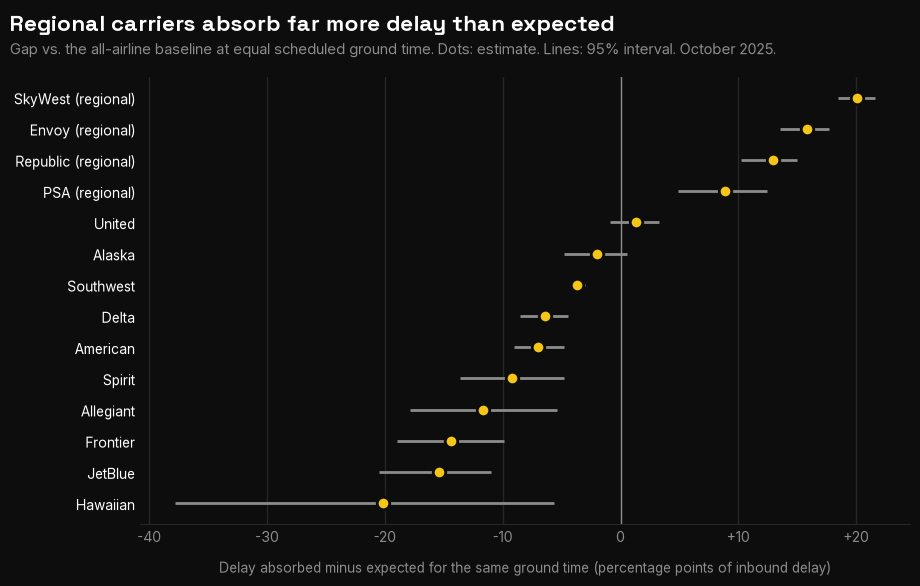

In [25]:
NAMES = {"AA": "American", "AS": "Alaska", "B6": "JetBlue", "DL": "Delta", "F9": "Frontier", "G4": "Allegiant",
         "HA": "Hawaiian", "MQ": "Envoy", "NK": "Spirit", "OH": "PSA", "OO": "SkyWest", "UA": "United",
         "WN": "Southwest", "YX": "Republic"}
REGIONAL = {"MQ", "OH", "OO", "YX"}

plot = gap.sort_values("gap_pp").reset_index(drop=True)
labels = [f"{NAMES[c]}{' (regional)' if c in REGIONAL else ''}" for c in plot["carrier"]]
y = np.arange(len(plot))

fig, ax = plt.subplots(figsize=(10, 6.2))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.axvline(0, color=BRAND["grey"], linewidth=1)
ax.hlines(y, plot["gap_lo"], plot["gap_hi"], color=BRAND["grey"], linewidth=2)
ax.plot(plot["gap_pp"], y, linestyle="none", marker="o", markersize=9, markerfacecolor=BRAND["yellow"],
        markeredgecolor=BRAND["black"], markeredgewidth=2)

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.tick_params(axis="y", labelcolor=BRAND["white"], length=0)
ax.tick_params(axis="x", length=0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}" if v else "0"))
ax.set_xlabel("Delay absorbed minus expected for the same ground time (percentage points of inbound delay)", labelpad=10)

fig.text(0.07, 0.95, "Regional carriers absorb far more delay than expected", fontsize=16, fontweight="bold",
         fontfamily=TITLE_FONT, ha="left", va="top")
fig.text(0.07, 0.90, "Gap vs. the all-airline baseline at equal scheduled ground time. Dots: estimate. Lines: 95% interval. October 2025.",
         fontsize=10.5, color=BRAND["grey"], ha="left", va="top")
fig.subplots_adjust(left=0.2, right=0.97, top=0.84, bottom=0.12)

fig.savefig(ROOT / "figures" / "airline_absorption_gap.png", dpi=150)
plt.show()

### Findings

- All four regional carriers (SkyWest, Envoy, Republic, PSA) absorb more inbound delay than the all-airline baseline predicts for the same scheduled ground time, by roughly +9 to +20 percentage points. Their 95% intervals exclude zero.
- Low-cost carriers (Spirit, Allegiant, Frontier) and JetBlue sit below the baseline, between about −9 and −15 points. Delta and American are modestly below, and United, Alaska and Southwest are close to the baseline.
- Hawaiian is the lowest estimate but has a very wide interval (about −38 to −6), so only the direction is reliable.
- The baseline is the pooled average, not an optimum, and regional carriers pull it upward. The ranking and the distance between groups are the finding; the sign for large carriers is partly mechanical.
- Regional carriers fly for partner brands and use smaller aircraft, so the gap may reflect operating model or schedule design rather than airline skill. This analysis cannot separate those.
- Intervals resample aircraft, so they capture dependence between flights of one aircraft but not shared daily shocks (weather, ATC programs).
- Southwest has negative absorption in absolute terms (−6.9% of inbound delay; median scheduled ground time 45 min), meaning late-inbound turns tend to leave later than they arrived. Its gap (−3.7 points) is the most precisely estimated, with a narrow interval from 18,807 pairs.
- Scheduled ground time alone does not rank the airlines: United schedules a median 74 min and sits at the baseline, while regionals schedule 46–49 min and absorb far more than expected.